# CodeT5 (Own- or Official-Pretrain) -- Score Eval + Calibration -- Colab


## Clean run -- what to change

This notebook **resumes from disk.** Each task type's results are cached to
`<CKPT_DIR>/score_eval_outputs/eval_cache/{task}_{TRACK}_full.pkl` and reloaded on
a re-run instead of being recomputed, so a committed cache reproduces the saved
tables and calibration numbers without a GPU. To reproduce *from scratch*:

1. **Environment.** Linux + GPU (Colab / WSL) recommended. The `official` track
   builds a `spawn` pool for its execution smoke test (works on any OS); the
   `own` track has no multiprocessing.
2. **Track + checkpoint.** Set `TRACK` (`"own"` / `"official"`) and, if you don't
   want the auto lowest-val-loss pick, `CKPT_NAME_OVERRIDE`, in the
   "Track, Checkpoint & Output Paths" cell.
3. **Force recompute.** Delete the cache for that track:
   `rm -rf <DATA_ROOT>/checkpoints/<RUN_NAME>/score_eval_outputs/eval_cache/`
   (or pass `resume=False` to `run_full_eval(...)`).
4. **Paths.** Colab original: `DRIVE_ROOT`. Local copy: `_localenv.py` (`TLM_DATA`
   env var); no edit needed.
5. **Data.** `data/finetune_data/sft_val_domain.jsonl` and the track's `.pt`
   checkpoint under `data/checkpoints/<RUN_NAME>/` must be present.


## Cell 1 -- Imports & Device

In [5]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import sys, os, re, json, math, time, random, pickle
from pathlib import Path
from collections import defaultdict

DRIVE_ROOT = Path('/content/drive/MyDrive/TLM_V03')
assert DRIVE_ROOT.exists(), f"{DRIVE_ROOT} not found -- upload the project to Drive first"
sys.path.insert(0, str(DRIVE_ROOT))


# -- "own" track pipeline (TLM's own tokenizer + token-id SEARCH/REPLACE) --
from src.model_config import ModelConfig
from src.tokenizer import TLM_Tokenizer
from src.data_set import make_sft_sr, apply_sr, split_lines_by_newline, join_lines

# -- "official" track pipeline (HF AutoTokenizer + text-level SEARCH/REPLACE) --
from src.codet5 import (
    TASK_TOKEN_NAME, decode_target_text, parse_sr_pairs_text, apply_sr_text,
    make_sft_sr_text,
)

# -- shared --
from src.eval.scorers import TASK_SCORERS

import torch
from transformers import AutoTokenizer, T5Config, T5ForConditionalGeneration
import numpy as np
import matplotlib.pyplot as plt

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}  |  PyTorch: {torch.__version__}")


Mounted at /content/drive
Device: cpu  |  PyTorch: 2.11.0+cpu


## Cell 2 -- Track, Checkpoint & Output Paths


In [6]:
TRACK = "own"   # "own" or "official" -- "own" == capacity-matched CodeT5 (9.9M, TLM_Tokenizer, no AutoTokenizer bug)
assert TRACK in ("own", "official")

RUN_NAME = "codet5_small_sft" if TRACK == "own" else "codet5_official_sft"
CKPT_NAME_OVERRIDE = None   # e.g. "codet5_official_sft_epoch_12_val0.1234.pt", or None to auto-pick

EVAL_PATH    = DRIVE_ROOT / "data" / "finetune_data" / "sft_val_domain.jsonl"
SFT_CKPT_DIR = DRIVE_ROOT / "data" / "checkpoints" / RUN_NAME

if CKPT_NAME_OVERRIDE is not None:
    CKPT_PATH = SFT_CKPT_DIR / CKPT_NAME_OVERRIDE
else:
    def _val_loss_from_name(p):
        m = re.search(r"val([0-9.]+)\.pt$", p.name)
        return float(m.group(1)) if m else float("inf")
    _ckpts = sorted(SFT_CKPT_DIR.glob(f"{RUN_NAME}_epoch_*_val*.pt"))
    assert _ckpts, f"No checkpoints found in {SFT_CKPT_DIR} for RUN_NAME={RUN_NAME!r}"
    CKPT_PATH = min(_ckpts, key=_val_loss_from_name)

OUTPUT_DIR     = SFT_CKPT_DIR / "score_eval_outputs"
EVAL_CACHE_DIR = OUTPUT_DIR / "eval_cache"
FIGURES_DIR    = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
EVAL_CACHE_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"TRACK={TRACK!r}  RUN_NAME={RUN_NAME!r}")
print(f"  checkpoint: {CKPT_PATH.name}  ({'OK' if CKPT_PATH.exists() else 'MISSING'})")
print(f"  eval data : {'OK' if EVAL_PATH.exists() else 'MISSING'}  {EVAL_PATH}")
print(f"  outputs -> {OUTPUT_DIR}")


TRACK='own'  RUN_NAME='codet5_small_sft'
  checkpoint: codet5_small_sft_epoch_25_val0.1553.pt  (OK)
  eval data : OK  /content/drive/MyDrive/TLM_V03/data/finetune_data/sft_val_domain.jsonl
  outputs -> /content/drive/MyDrive/TLM_V03/data/checkpoints/codet5_small_sft/score_eval_outputs


## Cell 3 -- Tokenizer & Model


In [ ]:
MAX_NEW_TOKENS = 512  # hard rule 

if TRACK == "own":
    TOKENIZER_PATH = str(DRIVE_ROOT / "src" / "tokenizer" / "tokenizer_tlm_small.json")
    tlm_config = ModelConfig()
    PAD_ID = tlm_config.special_token_ids["pad"]
    BOS_ID = tlm_config.special_token_ids["bos"]
    EOS_ID = tlm_config.special_token_ids["eos"]
    SEARCH_ID = tlm_config.special_token_ids["search"]
    REPLACE_ID = tlm_config.special_token_ids["replace"]

    tokenizer = TLM_Tokenizer(vocab_size=tlm_config.vocab_size)
    tokenizer.load(TOKENIZER_PATH)
    VOCAB_SIZE = tokenizer.tokenizer.get_vocab_size()

    t5_config = T5Config.from_pretrained("Salesforce/codet5-small")
    t5_config.vocab_size = VOCAB_SIZE
    t5_config.pad_token_id = PAD_ID
    t5_config.eos_token_id = EOS_ID
    t5_config.decoder_start_token_id = BOS_ID
    t5_config.d_model = 256
    t5_config.d_ff = 1024
    t5_config.num_layers = 4
    t5_config.num_decoder_layers = 4
    t5_config.num_heads = 4
    t5_config.d_kv=64

    model = T5ForConditionalGeneration(t5_config).to(device)

    GEN_KWARGS = dict(pad_token_id=PAD_ID, eos_token_id=EOS_ID, decoder_start_token_id=BOS_ID)
    EXCLUDE_CONF_IDS = {PAD_ID, EOS_ID, BOS_ID, SEARCH_ID, REPLACE_ID}

else:  # "official"
    TASK_MARKER_FMT = "<{}>"
    SEARCH_MARKER   = "<search>"
    REPLACE_MARKER  = "<replace>"

    # Colab's current default runtime is Python 3.13, which has no prebuilt
    # tokenizers wheel old enough to satisfy transformers==4.44.2 -- pinning
    # that combo (tried above, in an earlier version of this cell) silently
    # fails to install (pip aborts the whole resolve, nothing changes) and the
    # newer transformers/tokenizers stack stays active regardless of restarting
    # the runtime. That newer stack hits
    # "TypeError: Input must be a List[Union[str, AddedToken]]" loading this
    # checkpoint's special_tokens_map.json through the fast (Rust) tokenizer
    # backend (transformers/tokenization_utils_tokenizers.py) -- a real bug in
    # how that backend re-wraps CodeT5-small's special-tokens entries, not a
    # stale-import artifact. use_fast=False loads the slow, pure-Python
    # tokenizer instead, which sidesteps that code path entirely; no version
    # pin or runtime restart needed. Everything this notebook actually calls on
    # the tokenizer (encode/decode/convert_tokens_to_ids/add_special_tokens)
    # works identically on the slow tokenizer, just somewhat slower per call.
    tokenizer = AutoTokenizer.from_pretrained("Salesforce/codet5-small", use_fast=False)
    model = T5ForConditionalGeneration.from_pretrained("Salesforce/codet5-small").to(device)
    new_tokens = [TASK_MARKER_FMT.format(name) for name in TASK_TOKEN_NAME.values()] + [SEARCH_MARKER, REPLACE_MARKER]
    tokenizer.add_special_tokens({"additional_special_tokens": new_tokens})
    model.resize_token_embeddings(len(tokenizer))

    PAD_ID = tokenizer.pad_token_id
    EOS_ID = tokenizer.eos_token_id
    BOS_ID = tokenizer.bos_token_id
    SEARCH_ID = tokenizer.convert_tokens_to_ids(SEARCH_MARKER)
    REPLACE_ID = tokenizer.convert_tokens_to_ids(REPLACE_MARKER)

    GEN_KWARGS = dict(pad_token_id=PAD_ID, eos_token_id=EOS_ID)
    EXCLUDE_CONF_IDS = {PAD_ID, EOS_ID, SEARCH_ID, REPLACE_ID} | ({BOS_ID} if BOS_ID is not None else set())

_state = torch.load(CKPT_PATH, map_location=device)
model.load_state_dict(_state["model"])
model.eval()
model.config.use_cache = True

n_params = sum(p.numel() for p in model.parameters())
print(f"Loaded {CKPT_PATH.name}  |  epoch {_state.get('epoch')}  val_loss {_state.get('val_loss')}  "
      f"|  params {n_params/1e6:.3f}M")


Loaded codet5_small_sft_epoch_25_val0.1553.pt  |  epoch 25  val_loss 0.15529372467005506  |  params 9.906M


## Cell 4 -- Eval Data (held-out SFT val set, shared across every model on the ladder)

In [8]:
by_type = defaultdict(list)
with open(EVAL_PATH, encoding="utf-8") as f:
    for line in f:
        d = json.loads(line)
        by_type[d["type"]].append(d)

TASK_ORDER = ["rename", "simplify", "deduplicate", "remove_dead_code", "extract_method"]
print(f"eval records per type (EVAL_PATH = {EVAL_PATH.name}):")
for t in TASK_ORDER:
    print(f"  {t:20s}: {len(by_type.get(t, []))}")
print(f"  total              : {sum(len(v) for v in by_type.values())}")

OK_SCORE_THRESHOLD = {
    "rename": 0.999, "remove_dead_code": 0.999,
    "simplify": 0.85, "deduplicate": 0.85, "extract_method": 0.85,
}   # same thresholds/rationale as score_eval.ipynb -- kept in sync by hand


eval records per type (EVAL_PATH = sft_val_domain.jsonl):
  rename              : 750
  simplify            : 750
  deduplicate         : 750
  remove_dead_code    : 750
  extract_method      : 750
  total              : 3750


## Cell 5 -- Greedy Decode w/ Per-Token Confidence


In [9]:
@torch.no_grad()
def hf_generate_with_conf(enc_ids, max_new_tokens=MAX_NEW_TOKENS):
    input_ids = torch.tensor([enc_ids], dtype=torch.long, device=device)
    attn = torch.ones_like(input_ids)
    out = model.generate(
        input_ids=input_ids, attention_mask=attn, max_new_tokens=max_new_tokens,
        num_beams=1, do_sample=False, output_scores=True, return_dict_in_generate=True,
        **GEN_KWARGS,
    )
    seq = out.sequences[0].tolist()
    step_confs = [float(torch.softmax(s[0], dim=-1).max()) for s in out.scores]
    # seq[0] is decoder_start/bos (no associated score); step_confs[i] is the confidence
    # for seq[i + 1] -- same off-by-one convention as the TLM ladder's confs/dec_ids pairing.
    return seq, step_confs


def _content_confs(seq, step_confs):
    out = []
    for i in range(1, len(seq)):
        tok = seq[i]
        if tok in EXCLUDE_CONF_IDS:
            continue
        c = step_confs[i - 1] if i - 1 < len(step_confs) else None
        if c is not None:
            out.append(c)
    return out


def decode_one(d, ttype):
    """Returns dict(before_text, pred_text, gold_text, pred_after, is_trunc,
    mean_conf, min_conf, p05_conf) -- identical shape regardless of TRACK."""
    if TRACK == "own":
        res = make_sft_sr(d, tokenizer, tlm_config)
        if res is None:
            return None
        enc_ids, _, _ = res
        before_ids = tokenizer.encode(d["before"])
        after_ids  = tokenizer.encode(d["after"])
        gold_after_ids = join_lines(split_lines_by_newline(after_ids, tlm_config.special_token_ids["newline"]),
                                    tlm_config.special_token_ids["newline"])
        seq, step_confs = hf_generate_with_conf(enc_ids)
        pred_after_ids = apply_sr(before_ids, seq, tlm_config)
        before_text = tokenizer.decode(before_ids)
        pred_text   = tokenizer.decode(pred_after_ids) if pred_after_ids is not None else None
        gold_text   = tokenizer.decode(gold_after_ids)
        is_trunc    = seq[-1] != EOS_ID
    else:
        task_marker = TASK_MARKER_FMT.format(ttype)
        enc_text = task_marker + d["before"]
        enc_ids = tokenizer(enc_text, truncation=True, max_length=512).input_ids
        seq, step_confs = hf_generate_with_conf(enc_ids)
        pred_text_raw, is_trunc = decode_target_text(tokenizer, seq)
        hunks = parse_sr_pairs_text(pred_text_raw, SEARCH_MARKER, REPLACE_MARKER)
        pred_after_text = apply_sr_text(d["before"], hunks)
        before_text = d["before"]
        pred_text   = pred_after_text
        gold_text   = d["after"]

    content_confs = _content_confs(seq, step_confs)
    mean_conf = sum(content_confs) / len(content_confs) if content_confs else 0.0
    min_conf  = min(content_confs) if content_confs else mean_conf
    p05_conf  = float(np.percentile(content_confs, 5)) if content_confs else mean_conf

    return {"before_text": before_text, "pred_text": pred_text, "gold_text": gold_text,
            "is_trunc": is_trunc, "mean_conf": mean_conf, "min_conf": min_conf, "p05_conf": p05_conf}


## Cell 6 -- Full Eval Loop


In [10]:
PROGRESS_EVERY = 25

def _pick_representative(sample_records, k=5):
    if len(sample_records) <= k:
        return sample_records
    ranked = sorted(sample_records, key=lambda r: r["score"])
    n_low = k // 2
    picked = ranked[:n_low] + ranked[-(k - n_low):]
    seen, out = set(), []
    for r in picked:
        if id(r) not in seen:
            seen.add(id(r)); out.append(r)
    return out


def _ttype_cache_path(cache_dir, ttype):
    return cache_dir / f"{ttype}_{TRACK}_full.pkl"


def run_full_eval(by_type_dict, progress_every=PROGRESS_EVERY, cache_dir=EVAL_CACHE_DIR, resume=True):
    results = {}
    all_records = []
    t0 = time.perf_counter()
    n_done = 0
    n_total = sum(len(recs) for recs in by_type_dict.values())

    for ttype, recs in by_type_dict.items():
        cache_path = _ttype_cache_path(cache_dir, ttype)
        if resume and cache_path.exists():
            with open(cache_path, "rb") as f:
                cached = pickle.load(f)
            results[ttype] = cached["results_entry"]
            all_records.extend(cached["representative_records"])
            n_done += len(recs)
            r = results[ttype]
            print(f"--- [{ttype}] loaded from cache: {r['ok']}/{r['total']} ok, "
                  f"mean_score={sum(r['scores'])/max(len(r['scores']),1):.3f} ---", flush=True)
            continue

        print(f"\n--- [{ttype}] starting, {len(recs)} samples ---", flush=True)
        ok = trunc = parse_fail = total = 0
        scores, complexities, confs, min_confs, p05_confs = [], [], [], [], []
        sample_records = []
        for i, d in enumerate(recs):
            out = decode_one(d, ttype)
            if out is None:
                continue
            total += 1
            trunc += int(out["is_trunc"])
            if out["pred_text"] is None:
                parse_fail += 1

            score_result = TASK_SCORERS[ttype](out["before_text"], out["pred_text"], out["gold_text"])
            sample_score = score_result["score"]
            is_ok = sample_score >= OK_SCORE_THRESHOLD.get(ttype, 0.999)

            scores.append(sample_score)
            complexities.append(score_result.get("complexity"))
            confs.append(out["mean_conf"]); min_confs.append(out["min_conf"]); p05_confs.append(out["p05_conf"])
            if is_ok:
                ok += 1
            sample_records.append({"d": d, "pred_text": out["pred_text"], "gold_text": out["gold_text"],
                                   "before_text": out["before_text"], "mean_conf": out["mean_conf"],
                                   "min_conf": out["min_conf"], "p05_conf": out["p05_conf"],
                                   "is_ok": is_ok, "score": sample_score,
                                   "complexity": score_result.get("complexity")})
            n_done += 1
            if (i + 1) % progress_every == 0 or (i + 1) == len(recs):
                elapsed = time.perf_counter() - t0
                eta = (n_total - n_done) / max(n_done / max(elapsed, 1e-9), 1e-9)
                print(f"  [{ttype}] {i+1}/{len(recs)}  ok so far: {ok}  "
                      f"| overall {n_done}/{n_total}  elapsed {elapsed:.0f}s  ETA {eta:.0f}s", flush=True)

        results[ttype] = {"ok": ok, "total": total, "trunc": trunc, "parse_fail": parse_fail,
                          "scores": scores, "complexities": complexities,
                          "confs": confs, "min_confs": min_confs, "p05_confs": p05_confs}
        representative_records = _pick_representative(sample_records, k=5)
        all_records.extend(representative_records)
        with open(cache_path, "wb") as f:
            pickle.dump({"results_entry": results[ttype], "representative_records": representative_records}, f)
        mean_score = sum(scores) / max(len(scores), 1)
        print(f"{ttype:20s}: {ok:3d}/{total:<3d} ({ok/max(total,1)*100:5.1f}%)  mean_score={mean_score:.3f}  "
              f"trunc={trunc}  parse_fail={parse_fail}  [cached -> {cache_path.name}]")

    elapsed = time.perf_counter() - t0
    total_ok  = sum(v["ok"]    for v in results.values())
    total_tot = sum(v["total"] for v in results.values())
    print(f"\n{'OVERALL':20s}: {total_ok:3d}/{total_tot:<3d} ({total_ok/max(total_tot,1)*100:5.1f}%)  "
          f"elapsed {elapsed:.0f}s")
    return results, all_records, total_ok, total_tot


results, all_records, total_ok, total_tot = run_full_eval(by_type)


--- [remove_dead_code] loaded from cache: 596/750 ok, mean_score=0.896 ---
--- [rename] loaded from cache: 257/750 ok, mean_score=0.594 ---
--- [simplify] loaded from cache: 299/750 ok, mean_score=0.558 ---
--- [extract_method] loaded from cache: 185/750 ok, mean_score=0.462 ---
--- [deduplicate] loaded from cache: 175/747 ok, mean_score=0.479 ---

OVERALL             : 1512/3747 ( 40.4%)  elapsed 2s


## Cell 7 -- Headline Scorecard

task                 mean_score  applied_ok%      n
----------------------------------------------------
rename                    0.594        34.3%    750
simplify                  0.558        39.9%    750
deduplicate               0.479        23.4%    747
remove_dead_code          0.896        79.5%    750
extract_method            0.462        24.7%    750
----------------------------------------------------
OVERALL_SCORE             0.598        40.4%   3747


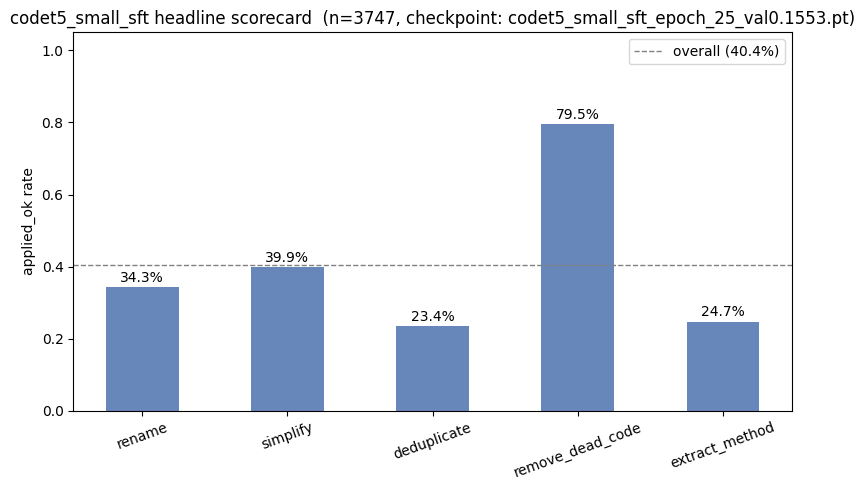

In [11]:
task_mean_scores = {}
for t in TASK_ORDER:
    if t not in results:
        continue
    task_mean_scores[t] = sum(results[t]["scores"]) / max(len(results[t]["scores"]), 1)
overall_score = sum(task_mean_scores.values()) / max(len(task_mean_scores), 1)

print(f"{'task':20s} {'mean_score':>10}  {'applied_ok%':>11}  {'n':>5}")
print("-" * 52)
for t in TASK_ORDER:
    if t not in results:
        continue
    r = results[t]
    ok_rate = r["ok"] / max(r["total"], 1)
    print(f"{t:20s} {task_mean_scores[t]:10.3f}  {ok_rate*100:10.1f}%  {r['total']:5d}")
print("-" * 52)
print(f"{'OVERALL_SCORE':20s} {overall_score:10.3f}  {total_ok/max(total_tot,1)*100:10.1f}%  {total_tot:5d}")

fig, ax = plt.subplots(figsize=(8, 5))
tasks_plot = [t for t in TASK_ORDER if t in results]
ok_rates = [results[t]["ok"] / max(results[t]["total"], 1) for t in tasks_plot]
bars = ax.bar(tasks_plot, ok_rates, color="#4C72B0", alpha=0.85, width=0.5)
for bar, val in zip(bars, ok_rates):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.015, f"{val:.1%}", ha="center", fontsize=10)
ax.axhline(total_ok/max(total_tot,1), color="gray", linestyle="--", linewidth=1,
          label=f"overall ({total_ok/max(total_tot,1):.1%})")
ax.set_ylim(0, 1.05); ax.set_ylabel("applied_ok rate")
ax.set_title(f"{RUN_NAME} headline scorecard  (n={total_tot}, checkpoint: {CKPT_PATH.name})")
ax.tick_params(axis="x", rotation=20)
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_headline_scorecard.png", dpi=150, bbox_inches="tight")
plt.show()


## Cell 8 -- Score vs. Complexity

Same discrete/quantile bucketing as `score_eval.ipynb` -- table only, no plot
(a monotonic per-task trend reads cleanly as numbers).

In [12]:
def _bucket_label_discrete(v, cap):
    if v is None:
        return "n/a"
    return str(v) if v < cap else f"{cap}+"

def _bucket_label_quantile(v, all_vals, n_buckets=3, labels=("short", "medium", "long")):
    if v is None or not all_vals:
        return "n/a"
    sorted_vals = sorted(all_vals)
    edges = [sorted_vals[int(len(sorted_vals) * i / n_buckets)] for i in range(1, n_buckets)]
    idx = sum(1 for e in edges if v > e)
    return labels[min(idx, len(labels) - 1)]

COMPLEXITY_BUCKETS = {
    "rename":           (lambda v, allv: _bucket_label_discrete(v, 4), ["1", "2", "3", "4+", "n/a"]),
    "remove_dead_code": (lambda v, allv: _bucket_label_discrete(v, 3), ["1", "2", "3+", "n/a"]),
    "simplify":         (lambda v, allv: _bucket_label_discrete(v, 3), ["1", "2", "3+", "n/a"]),
    "deduplicate":      (lambda v, allv: _bucket_label_discrete(v, 3), ["1", "2", "3+", "n/a"]),
    "extract_method":   (lambda v, allv: _bucket_label_quantile(v, allv), ["short", "medium", "long", "n/a"]),
}

def _grouped_scores_by_bucket(results_dict, ttype):
    r = results_dict.get(ttype)
    if not r:
        return {}
    bucket_fn, _ = COMPLEXITY_BUCKETS[ttype]
    all_vals = [c for c in r["complexities"] if c is not None]
    grouped = defaultdict(list)
    for score, cplx in zip(r["scores"], r["complexities"]):
        grouped[bucket_fn(cplx, all_vals)].append(score)
    return grouped

print(f"{'task':20s} {'bucket':>8}  {'n':>5}  {'mean_score':>10}")
print("-" * 50)
for ttype in TASK_ORDER:
    if ttype not in results:
        continue
    _, label_order = COMPLEXITY_BUCKETS[ttype]
    grouped = _grouped_scores_by_bucket(results, ttype)
    for l in label_order:
        if l not in grouped:
            continue
        m = sum(grouped[l]) / len(grouped[l])
        print(f"{ttype:20s} {l:>8}  {len(grouped[l]):>5}  {m:>10.3f}")


task                   bucket      n  mean_score
--------------------------------------------------
rename                      3      6       0.902
rename                     4+    736       0.591
rename                    n/a      8       0.593
simplify                    1    631       0.620
simplify                    2     99       0.261
simplify                   3+     20       0.075
deduplicate                 2    153       0.548
deduplicate                3+    562       0.470
deduplicate               n/a     32       0.305
remove_dead_code            1    284       0.934
remove_dead_code            2    320       0.917
remove_dead_code           3+    146       0.777
extract_method          short    327       0.375
extract_method         medium    226       0.577
extract_method           long    197       0.476


## Cell 9 -- Calibration: Teacher-Forced vs. Free-Decode


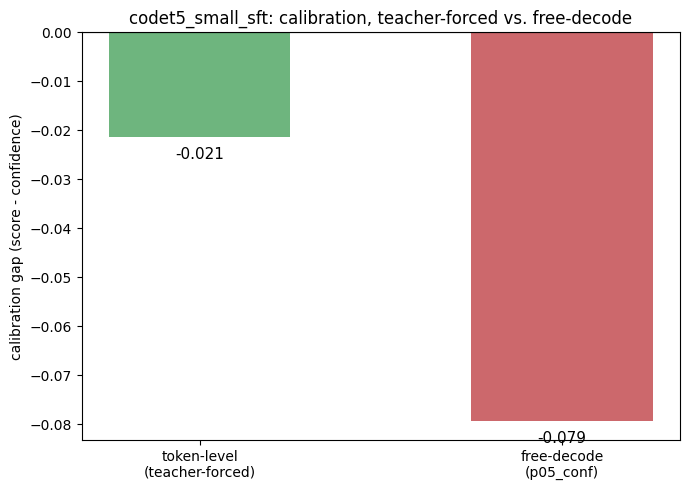

Token-level (teacher-forced) calibration gap : -0.021  (near 0 = well calibrated)
Free-decode calibration gap (p05_conf)        : -0.079  (large negative = overconfident)


In [13]:
def _reliability_gap(conf_list, score_list, n_bins=10):
    edges = [i / n_bins for i in range(n_bins + 1)]
    gaps = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        in_bin = [s for c, s in zip(conf_list, score_list) if lo <= c < hi or (hi == 1.0 and c == 1.0)]
        if in_bin:
            gaps.append(sum(in_bin) / len(in_bin) - (lo + hi) / 2)
    return sum(gaps) / max(len(gaps), 1)

pooled_p05_conf = [c for r in results.values() for c in r["p05_confs"]]
pooled_score    = [s for r in results.values() for s in r["scores"]]
free_decode_gap = _reliability_gap(pooled_p05_conf, pooled_score)

# Token-level, teacher-forced, T=1 -- one pass over the same val records used above.
# Rebuilds encoder/decoder id tensors per-record (no separate DataLoader/collate needed
# for a single forward-pass-per-batch pass over a few thousand records).
tf_conf, tf_correct = [], []
BATCH_TF = 16
_all_val_recs = [(ttype, d) for ttype in TASK_ORDER if ttype in by_type for d in by_type[ttype]]

with torch.no_grad():
    for start in range(0, len(_all_val_recs), BATCH_TF):
        chunk = _all_val_recs[start:start + BATCH_TF]
        enc_batches, dec_batches = [], []
        for ttype, d in chunk:
            if TRACK == "own":
                res = make_sft_sr(d, tokenizer, tlm_config)
                if res is None:
                    continue
                enc_ids, dec_ids, _ = res
            else:
                res = make_sft_sr_text(d, TASK_MARKER_FMT, SEARCH_MARKER, REPLACE_MARKER)
                if res is None:
                    continue
                enc_text, dec_text, _ = res
                enc_ids = tokenizer(enc_text, truncation=True, max_length=512).input_ids
                dec_ids = tokenizer(dec_text, truncation=True, max_length=512).input_ids
            enc_batches.append(enc_ids); dec_batches.append(dec_ids)
        if not enc_batches:
            continue

        max_se = max(len(x) for x in enc_batches)
        max_sd = max(len(x) for x in dec_batches)
        B = len(enc_batches)
        enc_t = torch.full((B, max_se), PAD_ID, dtype=torch.long)
        enc_a = torch.zeros((B, max_se), dtype=torch.long)
        dec_t = torch.full((B, max_sd), PAD_ID, dtype=torch.long)
        for i, (e, dd) in enumerate(zip(enc_batches, dec_batches)):
            enc_t[i, :len(e)] = torch.tensor(e, dtype=torch.long)
            enc_a[i, :len(e)] = 1
            dec_t[i, :len(dd)] = torch.tensor(dd, dtype=torch.long)
        enc_t, enc_a, dec_t = enc_t.to(device), enc_a.to(device), dec_t.to(device)

        if TRACK == "own":
            # dec_t carries a leading BOS (TLM convention) -- labels drop it, same as
            # supervised_finetuning_codet5_own_colab.ipynb's hf_step_batch.
            labels = dec_t[:, 1:].clone()
        else:
            # dec_t has no leading BOS (T5 tokenizer convention) -- labels used as-is,
            # same as src/codet5/training.py's hf_step_batch.
            labels = dec_t.clone()
        pad_mask = labels == PAD_ID
        labels_in = labels.clone(); labels_in[pad_mask] = -100

        out = model(input_ids=enc_t, attention_mask=enc_a, labels=labels_in)
        probs = torch.softmax(out.logits, dim=-1)
        top1_prob, top1_idx = probs.max(dim=-1)
        mask = ~pad_mask
        correct = (top1_idx == labels) & mask
        tf_conf.extend(top1_prob[mask].cpu().tolist())
        tf_correct.extend(correct[mask].cpu().tolist())

token_level_gap = _reliability_gap(tf_conf, [float(c) for c in tf_correct])

fig, ax = plt.subplots(figsize=(7, 5))
labels_x = ["token-level\n(teacher-forced)", "free-decode\n(p05_conf)"]
vals = [token_level_gap, free_decode_gap]
colors = ["#55A868" if abs(v) < 0.05 else "#C44E52" for v in vals]
bars = ax.bar(labels_x, vals, color=colors, alpha=0.85, width=0.5)
ax.axhline(0, color="black", linewidth=0.8)
for bar, v in zip(bars, vals):
    ax.annotate(f"{v:+.3f}", (bar.get_x() + bar.get_width()/2, v),
                textcoords="offset points", xytext=(0, 6 if v >= 0 else -16), ha="center", fontsize=11)
ax.set_ylabel("calibration gap (score - confidence)")
ax.set_title(f"{RUN_NAME}: calibration, teacher-forced vs. free-decode")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_calibration_story.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Token-level (teacher-forced) calibration gap : {token_level_gap:+.3f}  (near 0 = well calibrated)")
print(f"Free-decode calibration gap (p05_conf)        : {free_decode_gap:+.3f}  (large negative = overconfident)")


## Cell 10 -- Qualitative Samples

In [14]:
N_SHOW = 4

by_ttype_records = defaultdict(list)
for r in all_records:
    by_ttype_records[r["d"]["type"]].append(r)

for ttype in TASK_ORDER:
    recs = by_ttype_records.get(ttype)
    if not recs:
        continue
    print(f"\n\n{'#'*70}\n#  {ttype.upper()}\n{'#'*70}")
    for r in recs[:N_SHOW]:
        print(f"\n{'='*64}")
        print(f"  [{ttype.upper()}]  {'OK' if r['is_ok'] else 'WRONG/FAIL'}  "
              f"score={r['score']:.3f}  mean_conf={r['mean_conf']:.3f}  p05_conf={r['p05_conf']:.3f}")
        print(f"{'='*64}")
        print(f"\nBEFORE:\n{r['before_text']}")
        print(f"\nPRED AFTER:\n{r['pred_text'] if r['pred_text'] is not None else '(apply failed)'}")
        print(f"\nGOLD AFTER:\n{r['gold_text']}")




######################################################################
#  RENAME
######################################################################

  [RENAME]  WRONG/FAIL  score=0.000  mean_conf=0.973  p05_conf=0.808

BEFORE:
class SqlMigrator:
    def proc(self,tbl):
        q=f'SELECT * FROM {tbl}'
        r=self.exec(q)
        for row in r:
            if row['status']=='old':
                self.upd(tbl,row['id'],'archived')
                
    def exec(self,query):
    # Simulate query execution
        return[{'id':1,'status':'old'},{'id':2,'status':'new'}]
        
    def upd(self,tbl,rid,new_status):
        print(f'UPDATE {tbl} SET status = {new_status} WHERE id = {rid}')

PRED AFTER:
(apply failed)

GOLD AFTER:
class SqlMigrator:
    def process_table(self,table_name):
        query=f'SELECT * FROM {table_name}'
        results=self.execute_query(query)
        for row in results:
            if row['status']=='old':
                self.update_status(table_name,ro

## Latency Benchmark (wall-clock decode time)

Small held-out subsample, timed separately from the full eval loop above
(does not require re-running it) -- `model.generate` wall-clock latency per
sample and generated-tokens/sec, per task.

[rename] timed 18 samples (warmup 2 discarded)
[simplify] timed 18 samples (warmup 2 discarded)
[deduplicate] timed 18 samples (warmup 2 discarded)
[remove_dead_code] timed 18 samples (warmup 2 discarded)
[extract_method] timed 18 samples (warmup 2 discarded)

task                   mean_s   median_s    p95_s    tok/s    n
--------------------------------------------------------------
rename                  1.593      1.477    2.322    102.8   18
simplify                1.147      0.988    2.515    107.3   18
deduplicate             2.167      2.158    3.475    107.4   18
remove_dead_code        0.248      0.219    0.432    105.3   18
extract_method          0.922      0.817    1.484    108.1   18


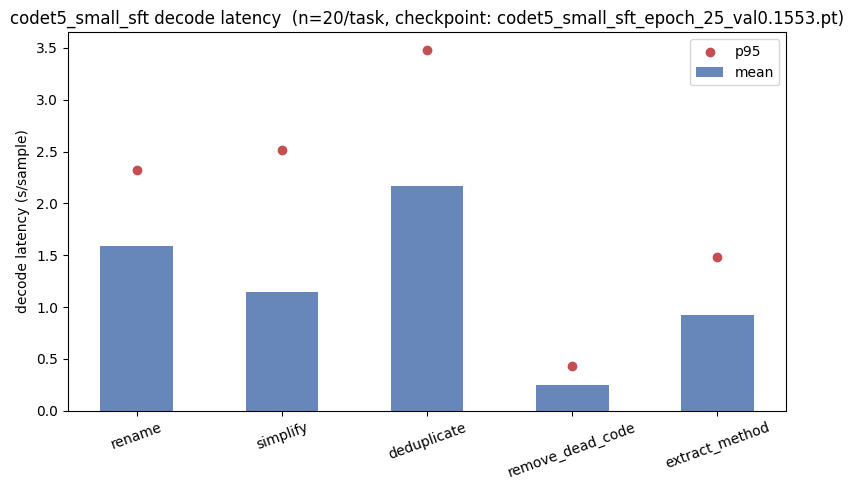

In [15]:
# -- Latency Benchmark: wall-clock decode time on a small held-out subsample --
# Separate from run_full_eval above -- does not touch its cache, no need to
# re-run the full eval to get this.
LATENCY_N_PER_TASK = 20   # small timing subsample, not a re-run of the full eval
LATENCY_WARMUP = 2        # discard first N decodes per task (cold-start effects)

def _build_enc_ids(d, ttype):
    if TRACK == "own":
        res = make_sft_sr(d, tokenizer, tlm_config)
        if res is None:
            return None
        enc_ids, _, _ = res
        return enc_ids
    else:
        task_marker = TASK_MARKER_FMT.format(ttype)
        enc_text = task_marker + d["before"]
        return tokenizer(enc_text, truncation=True, max_length=512).input_ids


def _decode_timed(d, ttype):
    enc_ids = _build_enc_ids(d, ttype)
    if enc_ids is None:
        return None
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    seq, _ = hf_generate_with_conf(enc_ids)
    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0

    n_gen = max(len(seq) - 1, 0)  # exclude decoder_start/bos (no generation step for it)
    return {"latency_s": elapsed, "n_tokens": n_gen, "tokens_per_s": n_gen / elapsed if elapsed > 0 else 0.0}


latency_raw = {}
for ttype in TASK_ORDER:
    recs = by_type.get(ttype, [])
    if not recs:
        continue
    subsample = recs[:LATENCY_N_PER_TASK]
    per_sample = []
    for d in subsample:
        r = _decode_timed(d, ttype)
        if r is not None:
            per_sample.append(r)
    latency_raw[ttype] = per_sample[LATENCY_WARMUP:] if len(per_sample) > LATENCY_WARMUP else per_sample
    print(f"[{ttype}] timed {len(latency_raw[ttype])} samples "
          f"(warmup {min(LATENCY_WARMUP, len(per_sample))} discarded)")


def _pctl(vals, p):
    if not vals:
        return 0.0
    s = sorted(vals)
    k = (len(s) - 1) * p / 100
    f, c = int(k), min(int(k) + 1, len(s) - 1)
    return s[f] + (s[c] - s[f]) * (k - f)


latency_summary = {}
for ttype, samples in latency_raw.items():
    lat = [s["latency_s"] for s in samples]
    tps = [s["tokens_per_s"] for s in samples]
    latency_summary[ttype] = {
        "n": len(samples),
        "mean_latency_s": sum(lat) / max(len(lat), 1),
        "median_latency_s": _pctl(lat, 50),
        "p95_latency_s": _pctl(lat, 95),
        "mean_tokens_per_s": sum(tps) / max(len(tps), 1),
    }

print(f"\n{'task':20s} {'mean_s':>8} {'median_s':>10} {'p95_s':>8} {'tok/s':>8} {'n':>4}")
print("-" * 62)
for t in TASK_ORDER:
    if t not in latency_summary:
        continue
    r = latency_summary[t]
    print(f"{t:20s} {r['mean_latency_s']:8.3f} {r['median_latency_s']:10.3f} "
          f"{r['p95_latency_s']:8.3f} {r['mean_tokens_per_s']:8.1f} {r['n']:4d}")

fig, ax = plt.subplots(figsize=(8, 5))
tasks_plot = [t for t in TASK_ORDER if t in latency_summary]
means = [latency_summary[t]["mean_latency_s"] for t in tasks_plot]
p95s = [latency_summary[t]["p95_latency_s"] for t in tasks_plot]
x = range(len(tasks_plot))
ax.bar(x, means, color="#4C72B0", alpha=0.85, width=0.5, label="mean")
ax.scatter(x, p95s, color="#C44E52", zorder=3, label="p95")
ax.set_xticks(list(x)); ax.set_xticklabels(tasks_plot, rotation=20)
ax.set_ylabel("decode latency (s/sample)")
ax.set_title(f"{RUN_NAME} decode latency  (n={LATENCY_N_PER_TASK}/task, checkpoint: {CKPT_PATH.name})")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_latency_benchmark.png", dpi=150, bbox_inches="tight")
plt.show()


## Cell 11 -- Save Summary

In [16]:
summary = {
    "track": TRACK, "run_name": RUN_NAME, "checkpoint": CKPT_PATH.name,
    "n_params_M": n_params / 1e6, "overall_score": overall_score,
    "overall_applied_ok_pct": total_ok / max(total_tot, 1) * 100, "n": total_tot,
    "per_task": {
        t: {"mean_score": task_mean_scores[t],
            "applied_ok_pct": results[t]["ok"] / max(results[t]["total"], 1) * 100,
            "n": results[t]["total"], "trunc": results[t]["trunc"], "parse_fail": results[t]["parse_fail"]}
        for t in TASK_ORDER if t in results
    },
    "calibration": {"token_level_gap": token_level_gap, "free_decode_gap": free_decode_gap},
    "latency_benchmark": latency_summary,
}
with open(OUTPUT_DIR / "summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(f"saved -> {OUTPUT_DIR / 'summary.json'}")
print(json.dumps(summary, indent=2))


saved -> /content/drive/MyDrive/TLM_V03/data/checkpoints/codet5_small_sft/score_eval_outputs/summary.json
{
  "track": "own",
  "run_name": "codet5_small_sft",
  "checkpoint": "codet5_small_sft_epoch_25_val0.1553.pt",
  "n_params_M": 9.90592,
  "overall_score": 0.5977061282846098,
  "overall_applied_ok_pct": 40.352281825460366,
  "n": 3747,
  "per_task": {
    "rename": {
      "mean_score": 0.5939076963516727,
      "applied_ok_pct": 34.266666666666666,
      "n": 750,
      "trunc": 12,
      "parse_fail": 10
    },
    "simplify": {
      "mean_score": 0.5578486590049402,
      "applied_ok_pct": 39.86666666666667,
      "n": 750,
      "trunc": 3,
      "parse_fail": 26
    },
    "deduplicate": {
      "mean_score": 0.4786782779626033,
      "applied_ok_pct": 23.427041499330656,
      "n": 747,
      "trunc": 16,
      "parse_fail": 58
    },
    "remove_dead_code": {
      "mean_score": 0.8959628548630938,
      "applied_ok_pct": 79.46666666666667,
      "n": 750,
      "trunc": 0